# Классификация растровых изображений с помощью kNN и поиск выбросов методом ODIN

Осьмушкин Н.М. 25222. Лабораторная работа 1.

Цель: сравнить меры близости при распознавании бинарных и полутоновых изображений и проверить kNN и ODIN на известных выбросах.

## Исходные данные

Шесть эталонов 16×16: диск, кольцо, две полосы, диагональ и рамка. Полутоновая версия — те же фигуры, фон 40 и объект 160.

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

NAMES = {
    \"euclidean\": \"евклидова\",
    \"sqeuclidean\": \"квадрат евклидовой\",
    \"manhattan\": \"манхэттенская\",
    \"chebyshev\": \"Чебышёва\",
    \"weighted\": \"взвешенная евклидова\",
}

def patterns():
    y, x = np.mgrid[:16, :16]
    c = 7.5
    r = np.hypot(y - c, x - c)
    masks = [
        r <= 4.2,
        (r >= 4.6) & (r <= 7.0),
        np.abs(y - c) <= 1.6,
        np.abs(x - c) <= 1.6,
        np.abs(y - x) <= 1.3,
        np.minimum(np.minimum(y, x), np.minimum(15 - y, 15 - x)) <= 1.4,
    ]
    return np.stack(masks).astype(float)

def noise(imgs, kind, mode, rng, flip_p=None):
    out = imgs.astype(float).copy()
    if kind == \"binary\":
        if flip_p is not None:
            p = flip_p
        elif mode == \"uniform\":
            p = 0.30
        else:
            p = np.where(rng.random(out.shape) < 0.35, 0.75, 0.08)
        flip = rng.random(out.shape) < p
        out[flip] = 1 - out[flip]
        return out
    if mode == \"uniform\":
        return np.clip(out + rng.uniform(-40, 40, out.shape), 0, 255)
    out = np.clip(out + rng.uniform(-8, 8, out.shape), 0, 255)
    hot = rng.random(out.shape) < 0.12
    out[hot] = rng.uniform(0, 255, out.shape)[hot]
    return out

def sample(clean, n, kind, mode, rng, flip_p=None):
    imgs = np.repeat(clean, n, axis=0)
    labels = np.repeat(np.arange(len(clean)), n)
    return noise(imgs, kind, mode, rng, flip_p), labels

def distance(a, b, metric, w):
    d = a[:, None] - b[None]
    if metric == \"euclidean\":
        return np.sqrt((d * d).sum(-1))
    if metric == \"sqeuclidean\":
        return (d * d).sum(-1)
    if metric == \"manhattan\":
        return np.abs(d).sum(-1)
    if metric == \"chebyshev\":
        return np.abs(d).max(-1)
    return np.sqrt((d * d * w).sum(-1))

def knn(dist, labels, k):
    votes = labels[np.argsort(dist, axis=1)[:, :k]]
    pred = np.empty(len(dist), dtype=int)
    for i, row in enumerate(votes):
        classes, counts = np.unique(row, return_counts=True)
        best = classes[counts == counts.max()]
        pred[i] = best[0] if len(best) == 1 else next(c for c in row if c in best)
    return pred

def pixel_weights(clean):
    var = clean.var(0).ravel()
    return var / var.mean()

binary = patterns()
gray = np.where(binary > 0, 160.0, 40.0)

fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for i, ax in enumerate(axes):
    ax.imshow(binary[i], cmap=\"gray_r\", vmin=0, vmax=1)
    ax.set_title(f\"класс {i}\")
    ax.axis(\"off\")
fig.suptitle(\"Эталоны\")
fig.tight_layout()
plt.show()

## Зашумление

Равномерный шум одинаков для всех пикселей: переворот с вероятностью 0,30 либо добавка ±40.

Неравномерный шум сильнее портит часть пикселей. У бинарных 35 % пикселей переворачиваются с вероятностью 0,75. У полутоновых 12 % пикселей заменяются случайной яркостью.

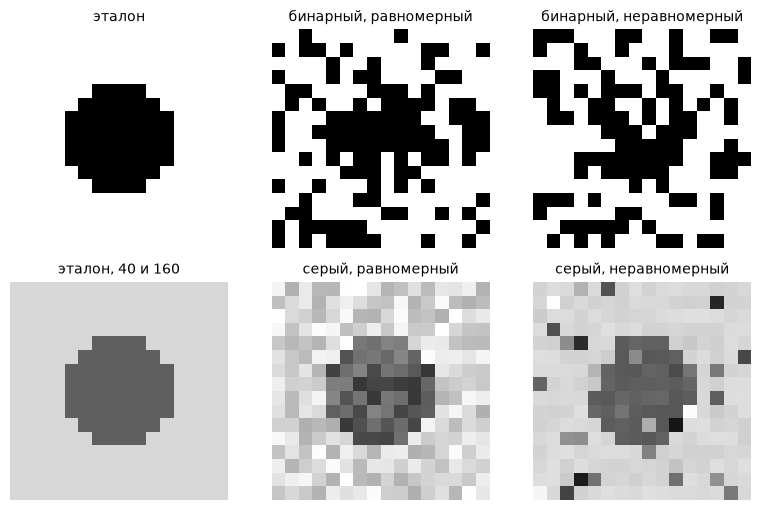

In [3]:
rng = np.random.default_rng(1)
shown = [
    (binary[0], "эталон", 1),
    (noise(binary[0:1], "binary", "uniform", rng)[0], "бинарный, равномерный", 1),
    (noise(binary[0:1], "binary", "nonuniform", rng)[0], "бинарный, неравномерный", 1),
    (gray[0], "эталон, 40 и 160", 255),
    (noise(gray[0:1], "gray", "uniform", rng)[0], "серый, равномерный", 255),
    (noise(gray[0:1], "gray", "nonuniform", rng)[0], "серый, неравномерный", 255),
]
fig, axes = plt.subplots(2, 3, figsize=(8, 5.2))
for ax, (img, title, vmax) in zip(axes.ravel(), shown):
    ax.imshow(img, cmap="gray_r", vmin=0, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()


## Классификация

На класс берётся 24 обучающих и 40 тестовых копий. k — сколько ближайших соседей нужно набрать. Класс ставится по большинству их меток. Сравниваются пять мер и k = 1, 3, 5, 7, 11.

In [4]:
clean = {"binary": binary, "gray": gray}
w = {kind: pixel_weights(clean[kind]) for kind in clean}
rows = []
for series, (kind, mode) in enumerate([
    ("binary", "uniform"),
    ("binary", "nonuniform"),
    ("gray", "uniform"),
    ("gray", "nonuniform"),
]):
    rng = np.random.default_rng(7 + series)
    train, train_y = sample(clean[kind], 24, kind, mode, rng)
    test, test_y = sample(clean[kind], 40, kind, mode, rng)
    train = train.reshape(len(train), -1)
    test = test.reshape(len(test), -1)
    for metric in NAMES:
        dist = distance(test, train, metric, w[kind])
        for k in (1, 3, 5, 7, 11):
            acc = float(np.mean(knn(dist, train_y, k) == test_y))
            rows.append((kind, mode, metric, k, acc))
            print(f"{kind:7} {mode:11} {NAMES[metric]:22} k={k:<2} {acc * 100:5.1f}%")


binary  uniform     евклидова              k=1   90.8%
binary  uniform     евклидова              k=3   95.0%
binary  uniform     евклидова              k=5   97.5%
binary  uniform     евклидова              k=7   96.7%
binary  uniform     евклидова              k=11  97.9%
binary  uniform     квадрат евклидовой     k=1   90.8%
binary  uniform     квадрат евклидовой     k=3   95.0%
binary  uniform     квадрат евклидовой     k=5   97.5%
binary  uniform     квадрат евклидовой     k=7   96.7%
binary  uniform     квадрат евклидовой     k=11  97.9%
binary  uniform     манхэттенская          k=1   90.8%
binary  uniform     манхэттенская          k=3   95.0%
binary  uniform     манхэттенская          k=5   97.5%
binary  uniform     манхэттенская          k=7   96.7%
binary  uniform     манхэттенская          k=11  97.9%
binary  uniform     Чебышёва               k=1   16.7%
binary  uniform     Чебышёва               k=3   16.7%
binary  uniform     Чебышёва               k=5   16.7%
binary  un

## Результаты

| Изображение | Шум | Точность | Лучший вариант |
|---|---|---|---|
| Бинарное | Равномерный | 97,9 % | евклидова, k = 11 |
| Бинарное | Неравномерный | 97,9 % | взвешенная евклидова, k = 7 |
| Полутоновое | Равномерный | 100 % | евклидова, k = 1 |
| Полутоновое | Неравномерный | 100 % | евклидова, k = 1 |

На бинарных картинках евклидова норма, её квадрат и манхэттенская метрика совпадают: пиксель отличается на 0 или 1. Расстояние Чебышёва даёт 16,7 %. После одного отличия расстояние равно 1, соседей упорядочить нельзя.

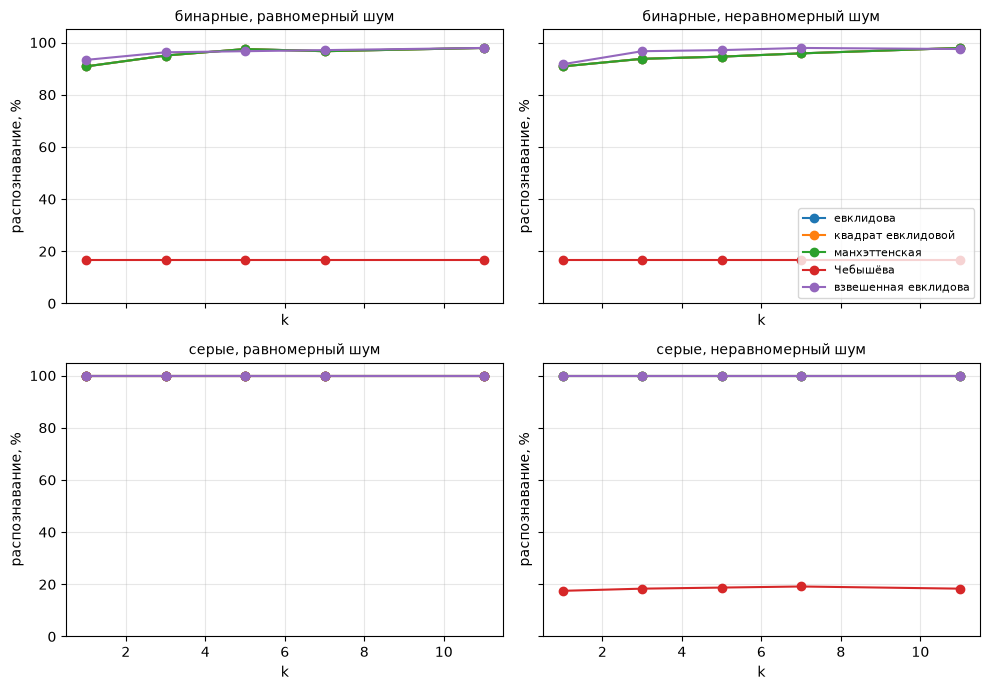

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
cases = [
    ("binary", "uniform", "бинарные, равномерный шум"),
    ("binary", "nonuniform", "бинарные, неравномерный шум"),
    ("gray", "uniform", "серые, равномерный шум"),
    ("gray", "nonuniform", "серые, неравномерный шум"),
]
for ax, (kind, mode, title) in zip(axes.ravel(), cases):
    for metric in NAMES:
        pts = [row for row in rows if row[:3] == (kind, mode, metric)]
        ax.plot([p[3] for p in pts], [100 * p[4] for p in pts], marker="o", label=NAMES[metric])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("k")
    ax.set_ylabel("распознавание, %")
    ax.set_ylim(0, 105)
    ax.grid(True, alpha=0.3)
axes[0, 1].legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()


## Выбросы

Тип 0 — 18 картинок с чужой меткой и 3 случайных растра. Тип 1 — тип 0, который не нашёл kNN. Тип 2 — тип 0, который не нашёл ODIN.

kNN проверяет объект по пяти соседям, исключив его самого. ODIN считает, сколько точек выбрало объект своим соседом. Выброс — нулевая входящая степень.

In [6]:
rng = np.random.default_rng(7)
imgs, labels = sample(binary, 20, "binary", "uniform", rng, flip_p=0.06)
labels = labels.copy()
picked = [i for cls in range(6) for i in rng.choice(np.flatnonzero(labels == cls), 3, replace=False)]
for i in picked:
    other = int(rng.integers(0, 5))
    labels[i] = other + (other >= labels[i])
imgs = np.concatenate([imgs, rng.integers(0, 2, size=(3, 16, 16))])
labels = np.concatenate([labels, rng.integers(0, 6, size=3)])
group = np.array(["inlier"] * 120)
group[list(picked)] = "label"
group = np.concatenate([group, ["spatial"] * 3])

flat = imgs.reshape(len(imgs), -1).astype(float)
dist = distance(flat, flat, "euclidean", None)
np.fill_diagonal(dist, np.inf)
knn_flag = knn(dist, labels, 5) != labels
indegree = np.bincount(np.argsort(dist, axis=1)[:, :5].ravel(), minlength=len(flat))
odin_flag = indegree < 1
bad = group != "inlier"

print("типа 0:", bad.sum())
print("типа 1, kNN не нашёл:", (bad & ~knn_flag).sum())
print("типа 2, ODIN не нашёл:", (bad & ~odin_flag).sum())
print("kNN: TP", (bad & knn_flag).sum(), "FP", (~bad & knn_flag).sum(), "FN", (bad & ~knn_flag).sum())
print("ODIN: TP", (bad & odin_flag).sum(), "FP", (~bad & odin_flag).sum(), "FN", (bad & ~odin_flag).sum())

типа 0: 21
типа 1, kNN не нашёл: 0
типа 2, ODIN не нашёл: 16
kNN: TP 21 FP 1 FN 0
ODIN: TP 5 FP 33 FN 16


## Выводы

На бинарных изображениях лучшая точность 97,9 %. Евклидова, квадрат евклидовой и манхэттенская нормы совпадают. Чебышёв на бинарных данных даёт 16,7 %, а при редкой сильной замене пикселей портится и на полутоновых.

kNN нашёл все 21 выброс типа 0. ODIN нашёл 5 и пометил 33 обычные точки. На этих данных надёжнее kNN.